In [9]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

def load_audio(file_path, sr=22050):
    """Q2.1: Loads audio, returns signal and sample rate."""
    y, sr = librosa.load(file_path, sr=sr)
    duration = librosa.get_duration(y=y, sr=sr)
    print(f"Loaded {file_path} | SR: {sr} | Duration: {duration:.2f}s")
    return y, sr


In [ ]:
def preprocess_audio(y, top_db=20):
    """Q2.2 & Q2.3: Normalization and Silence Removal."""
    y_norm = librosa.util.normalize(y)
    y_trimmed, _ = librosa.effects.trim(y_norm, top_db=top_db)
    
    return y_trimmed

In [ ]:
def extract_features(y, sr, n_mfcc=13):
    """Q3.1 & Q3.2: Extract MFCCs, Deltas, Spectral features."""

    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)

    delta_mfcc = librosa.feature.delta(mfccs)
    delta2_mfcc = librosa.feature.delta(mfccs, order=2)
    
    spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
    spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    
    features = np.vstack([mfccs, delta_mfcc, delta2_mfcc, spec_cent, spec_bw])
    
    return features

In [ ]:
def aggregate_features(features):
    """Q3.4: Aggregation (Mean + Std Dev)."""

    mean = np.mean(features, axis=1)
    std = np.std(features, axis=1)

    global_feature = np.concatenate([mean, std])
    return global_feature

In [ ]:
try:
    y, sr = load_audio(librosa.ex('trumpet'))
    
    y_clean = preprocess_audio(y)
    

    frames = librosa.util.frame(y_clean, frame_length=int(sr*0.025), hop_length=int(sr*0.0125))
    
    feats = extract_features(y_clean, sr)
    
    final_vector = aggregate_features(feats)
    
    print(f"Feature Matrix Shape: {feats.shape}")
    print(f"Final Vector Shape: {final_vector.shape}")
    
except Exception as e:
    print(f"Error: {e}")

Loaded /root/.cache/librosa/sorohanro_-_solo-trumpet-06.ogg | SR: 22050 | Duration: 5.33s
Feature Matrix Shape: (41, 132)
Final Vector Shape: (82,)


In [ ]:
from sklearn.model_selection import train_test_split

np.random.seed(42)
X_dummy = np.random.rand(100, 86) 
y_dummy = np.random.randint(0, 5, 100) 


X_train, X_test, y_train, y_test = train_test_split(X_dummy, y_dummy, test_size=0.2, random_state=42)

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='rbf', C=1.0, probability=True))
])

# Train
pipeline.fit(X_train, y_train)

# Predict
y_pred = pipeline.predict(X_test)

In [16]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

acc = accuracy_score(y_test, y_pred)

In [ ]:
print(f"Accuracy: {acc:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.25

Classification Report:
               precision    recall  f1-score   support

           1       0.28      0.83      0.42         6
           2       0.00      0.00      0.00         5
           3       0.00      0.00      0.00         5
           4       0.00      0.00      0.00         4

    accuracy                           0.25        20
   macro avg       0.07      0.21      0.10        20
weighted avg       0.08      0.25      0.12        20



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

pipeline_forest = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Train
pipeline_forest.fit(X_train, y_train)

# Predict
y_pred = pipeline_forest.predict(X_test)

In [21]:
print(f"Accuracy: {acc:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.25

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.45      0.83      0.59         6
           2       0.33      0.40      0.36         5
           3       0.00      0.00      0.00         5
           4       0.00      0.00      0.00         4

    accuracy                           0.35        20
   macro avg       0.16      0.25      0.19        20
weighted avg       0.22      0.35      0.27        20



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Confusion Matrix:
 [[0 0 0 0 0]
 [0 5 1 0 0]
 [0 2 2 1 0]
 [1 1 2 0 1]
 [0 3 1 0 0]]


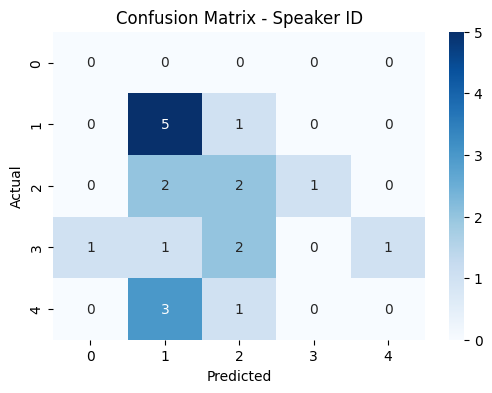

In [22]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Visualization
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d')
plt.title('Confusion Matrix - Speaker ID')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

for svm

Confusion Matrix:
 [[5 1 0 0]
 [5 0 0 0]
 [5 0 0 0]
 [3 1 0 0]]


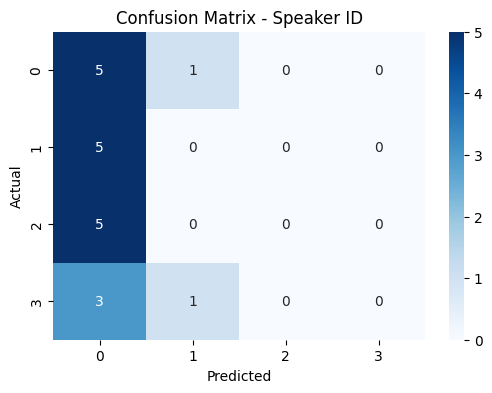

In [18]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Visualization
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d')
plt.title('Confusion Matrix - Speaker ID')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [3]:
import os
import librosa
import soundfile as sf
import numpy as np

# Configuration
ROOT_DIR = './VoxCeleb1/wav'
MOCK_SPEAKERS = ['id10001', 'id10002'] # Simulating 2 speakers
SAMPLES_PER_SPEAKER = 5

def create_mock_dataset():
    print(f"Creating mock dataset at: {os.path.abspath(ROOT_DIR)}")
    
    # Load a built-in example audio to use as a base
    # We use 'libri1' (male) and 'libri2' (female) if available, or just split one file
    try:
        y_base, sr = librosa.load(librosa.ex('libri1'), sr=16000)
    except:
        # Fallback if internet is restricted: generate noise
        print("Could not download sample. Generating synthetic audio...")
        y_base = np.random.uniform(-0.1, 0.1, 16000*10) # 10s of noise
        sr = 16000

    # Create folders and files
    for i, speaker_id in enumerate(MOCK_SPEAKERS):
        speaker_path = os.path.join(ROOT_DIR, speaker_id, 'video_session_1')
        os.makedirs(speaker_path, exist_ok=True)
        
        print(f"Generating data for {speaker_id}...")
        
        # Modify audio slightly to simulate different "speakers" or segments
        # (Pitch shifting or just slicing different parts)
        step = len(y_base) // (SAMPLES_PER_SPEAKER + 1)
        
        for j in range(SAMPLES_PER_SPEAKER):
            # Slice a different part of the audio for each file
            start = j * step
            end = start + step
            y_segment = y_base[start:end]
            
            # Artificial variation: Pitch shift different speakers differently
            if i == 1: 
                y_segment = librosa.effects.pitch_shift(y_segment, sr=sr, n_steps=4)
            
            filename = f"{speaker_path}/{j:05d}.wav"
            sf.write(filename, y_segment, sr)
            
    print("\n✅ Mock dataset created successfully!")
    print(f"You can now run the training script.")

if __name__ == "__main__":
    create_mock_dataset()

Creating mock dataset at: /content/VoxCeleb1/wav


Generating data for id10001...
Generating data for id10002...

✅ Mock dataset created successfully!
You can now run the training script.


Found 2 speakers. Processing files...
Dataset Built: 10 samples, 82 features.
Training SVM Model...

--- RESULTS ---
Accuracy: 50.00%
              precision    recall  f1-score   support

     id10001       0.00      0.00      0.00         1
     id10002       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


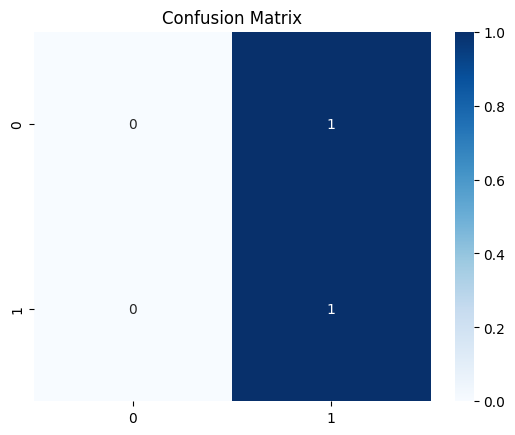

In [5]:
import os
import glob
import numpy as np
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# --- CONFIGURATION ---
DATASET_PATH = './VoxCeleb1/wav'  # Points to the data you just created
SAMPLE_RATE = 16000
DURATION = 3.0       # Fix duration for consistency

# --- STEP 2: Preprocessing ---

def load_audio(file_path):
    """Q2.1: Load audio file."""
    try:
        y, sr = librosa.load(file_path, sr=SAMPLE_RATE)
        return y, sr
    except Exception as e:
        print(f"Error loading {file_path}: {e}")
        return None, None

def preprocess_audio(y):
    """Q2.2 & Q2.3: Normalization and Silence Removal."""
    # 1. Normalize amplitude
    y_norm = librosa.util.normalize(y)
    
    # 2. Silence Removal
    y_trimmed, _ = librosa.effects.trim(y_norm, top_db=20)
    
    # Pad or crop to fixed length
    target_len = int(DURATION * SAMPLE_RATE)
    if len(y_trimmed) > target_len:
        y_trimmed = y_trimmed[:target_len]
    else:
        y_trimmed = np.pad(y_trimmed, (0, max(0, target_len - len(y_trimmed))))
        
    return y_trimmed

# --- STEP 3: Feature Engineering ---

def extract_features(y, sr):
    """Q3.1 & Q3.2: Extract MFCCs, Deltas, and Spectral Features."""
    
    # 1. MFCC
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    
    # 2. Deltas
    delta_mfcc = librosa.feature.delta(mfcc)
    delta2_mfcc = librosa.feature.delta(mfcc, order=2)
    
    # 3. Spectral Features
    spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
    spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    
    # Stack features
    features = np.vstack([mfcc, delta_mfcc, delta2_mfcc, spec_cent, spec_bw])
    
    return features

def aggregate_features(features):
    """Q3.4: Time Aggregation (Mean + Std)."""
    mean_feat = np.mean(features, axis=1)
    std_feat = np.std(features, axis=1)
    return np.concatenate([mean_feat, std_feat])

# --- PIPELINE ---

def build_dataset(root_dir):
    X = []
    y = []
    
    # Look for speaker folders (id10001, id10002...)
    speaker_dirs = [d for d in os.listdir(root_dir) if d.startswith('id')]
    
    print(f"Found {len(speaker_dirs)} speakers. Processing files...")
    
    for speaker in speaker_dirs:
        wav_files = glob.glob(os.path.join(root_dir, speaker, '**/*.wav'), recursive=True)
        
        for wav_path in wav_files:
            sig, sr = load_audio(wav_path)
            if sig is None: continue
            
            sig_proc = preprocess_audio(sig)
            
            feats_frames = extract_features(sig_proc, sr)
            final_vector = aggregate_features(feats_frames)
            
            X.append(final_vector)
            y.append(speaker)
            
    return np.array(X), np.array(y)

# --- EXECUTION ---

if __name__ == "__main__":
    if not os.path.exists(DATASET_PATH):
        print("Dataset not found.")
    else:
        # 1. Build Dataset
        X, y = build_dataset(DATASET_PATH)
        print(f"Dataset Built: {X.shape[0]} samples, {X.shape[1]} features.")
        
        # 2. Split
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        
        # 3. Train
        print("Training SVM Model...")
        pipeline = Pipeline([
            ('scaler', StandardScaler()), 
            ('svm', SVC(kernel='rbf', probability=True))
        ])
        pipeline.fit(X_train, y_train)
        
        # 4. Evaluate
        print("\n--- RESULTS ---")
        y_pred = pipeline.predict(X_test)
        
        print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
        print(classification_report(y_test, y_pred))
        
        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title('Confusion Matrix')
        plt.show()

Found 2 speakers. Processing...
Dataset Shape: (10, 82)
Training Random Forest Model...

Accuracy: 50.00%
              precision    recall  f1-score   support

     id10001       0.00      0.00      0.00         1
     id10002       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


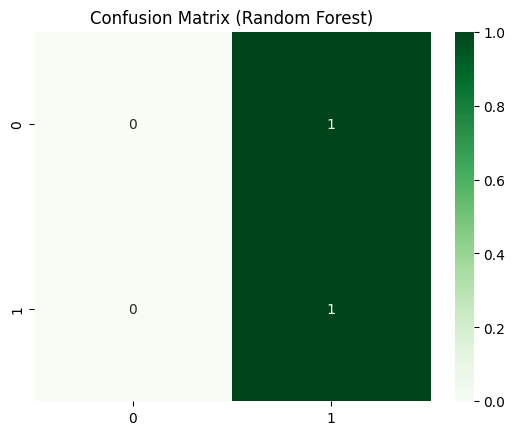

In [6]:
import os
import glob
import numpy as np
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier  # <--- CHANGED
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# --- CONFIGURATION ---
DATASET_PATH = './VoxCeleb1/wav'
SAMPLE_RATE = 16000
DURATION = 3.0

# --- PREPROCESSING & FEATURES (Same as before) ---
def load_audio(file_path):
    try:
        y, sr = librosa.load(file_path, sr=SAMPLE_RATE)
        return y, sr
    except:
        return None, None

def preprocess_audio(y):
    y_norm = librosa.util.normalize(y)
    y_trimmed, _ = librosa.effects.trim(y_norm, top_db=20)
    target_len = int(DURATION * SAMPLE_RATE)
    if len(y_trimmed) > target_len:
        y_trimmed = y_trimmed[:target_len]
    else:
        y_trimmed = np.pad(y_trimmed, (0, max(0, target_len - len(y_trimmed))))
    return y_trimmed

def extract_features(y, sr):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    delta_mfcc = librosa.feature.delta(mfcc)
    delta2_mfcc = librosa.feature.delta(mfcc, order=2)
    spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
    spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    features = np.vstack([mfcc, delta_mfcc, delta2_mfcc, spec_cent, spec_bw])
    return features

def aggregate_features(features):
    mean_feat = np.mean(features, axis=1)
    std_feat = np.std(features, axis=1)
    return np.concatenate([mean_feat, std_feat])

def build_dataset(root_dir):
    X, y = [], []
    speaker_dirs = [d for d in os.listdir(root_dir) if d.startswith('id')]
    print(f"Found {len(speaker_dirs)} speakers. Processing...")
    
    for speaker in speaker_dirs:
        wav_files = glob.glob(os.path.join(root_dir, speaker, '**/*.wav'), recursive=True)
        for wav_path in wav_files:
            sig, sr = load_audio(wav_path)
            if sig is None: continue
            sig = preprocess_audio(sig)
            feats = aggregate_features(extract_features(sig, sr))
            X.append(feats)
            y.append(speaker)
    return np.array(X), np.array(y)

# --- MAIN EXECUTION ---
if __name__ == "__main__":
    if not os.path.exists(DATASET_PATH):
        print("Dataset not found.")
    else:
        # 1. Build Dataset
        X, y = build_dataset(DATASET_PATH)
        print(f"Dataset Shape: {X.shape}")
        
        # 2. Split
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        
        # 3. Random Forest Pipeline
        print("Training Random Forest Model...")
        pipeline = Pipeline([
            ('scaler', StandardScaler()), 
            # n_estimators=100 means 100 trees
            ('rf', RandomForestClassifier(n_estimators=100, random_state=42)) 
        ])
        
        pipeline.fit(X_train, y_train)
        
        # 4. Evaluate
        y_pred = pipeline.predict(X_test)
        print(f"\nAccuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
        print(classification_report(y_test, y_pred))
        
        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Greens') # Changed color to Green
        plt.title('Confusion Matrix (Random Forest)')
        plt.show()

lstm

Processing sequences for 2 speakers...
Data Shape: (10, 100, 13)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        19,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,114 (86.38 KB)

 Trainable params: 22,114 (86.38 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM...
Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 0.6847 - val_accuracy: 0.5000 - val_loss: 0.6971
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.5000 - loss: 0.6776 - val_accuracy: 0.5000 - val_loss: 0.6945
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.7500 - loss: 0.6666 - val_accuracy: 0.5000 - val_loss: 0.6911
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.7500 - loss: 0.6601 - val_accuracy: 0.5000 - val_loss: 0.6863
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.8750 - loss: 0.6500 - val_accuracy: 0.5000 - val_loss: 0.6800
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.8750 - loss: 0.6522 - val_accuracy: 0.5000 - val_loss: 0.6732
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.7500 - loss: 0.6379 - val_accuracy: 0.5000 - val_loss: 0.6626
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.7500 - loss: 0.6332 - val_accuracy: 1.0

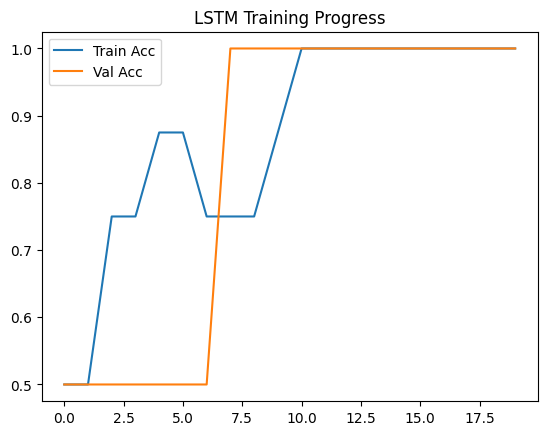

In [7]:
import os
import glob
import numpy as np
import librosa
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# --- CONFIGURATION ---
DATASET_PATH = './VoxCeleb1/wav'
SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 13
# Calculate expected number of frames roughly: (Duration * SR) / Hop_Length
# Librosa default hop_length is 512. 
# 3s * 16000 / 512 ≈ 94 frames. We fix it to 100 for safety.
MAX_TIME_STEPS = 100 

# --- STEP 2 & 3: Sequence Preparation ---

def load_and_process(file_path):
    try:
        y, sr = librosa.load(file_path, sr=SAMPLE_RATE)
        # Normalize & Trim
        y = librosa.util.normalize(y)
        y, _ = librosa.effects.trim(y, top_db=20)
        
        # Extract MFCCs (Sequence)
        # Shape: (n_mfcc, time_steps)
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
        
        # Transpose to (time_steps, n_mfcc) for LSTM
        mfcc = mfcc.T
        
        # Pad or Truncate to MAX_TIME_STEPS
        if mfcc.shape[0] > MAX_TIME_STEPS:
            mfcc = mfcc[:MAX_TIME_STEPS, :]
        else:
            pad_width = MAX_TIME_STEPS - mfcc.shape[0]
            mfcc = np.pad(mfcc, ((0, pad_width), (0, 0)), mode='constant')
            
        return mfcc
    except:
        return None

def build_dataset_lstm(root_dir):
    X = []
    y = []
    speaker_dirs = [d for d in os.listdir(root_dir) if d.startswith('id')]
    
    print(f"Processing sequences for {len(speaker_dirs)} speakers...")
    
    for speaker in speaker_dirs:
        wav_files = glob.glob(os.path.join(root_dir, speaker, '**/*.wav'), recursive=True)
        for wav_path in wav_files:
            feats = load_and_process(wav_path)
            if feats is not None:
                X.append(feats)
                y.append(speaker)
                
    return np.array(X), np.array(y)

# --- EXECUTION ---

if __name__ == "__main__":
    if not os.path.exists(DATASET_PATH):
        print("Dataset not found.")
    else:
        # 1. Load Data
        X, y = build_dataset_lstm(DATASET_PATH)
        print(f"Data Shape: {X.shape}") # Should be (Samples, 100, 13)
        
        # 2. Encode Labels (String -> Integer -> One-Hot)
        le = LabelEncoder()
        y_int = le.fit_transform(y)
        y_cat = to_categorical(y_int)
        
        # 3. Split
        X_train, X_test, y_train, y_test = train_test_split(X, y_cat, test_size=0.2, random_state=42)
        
        # 4. Build LSTM Model
        model = Sequential([
            Input(shape=(MAX_TIME_STEPS, N_MFCC)),
            # LSTM Layer: Return sequences=False because we want one vector at the end
            LSTM(64, return_sequences=False), 
            Dropout(0.3),
            Dense(32, activation='relu'),
            # Output Layer: Units = Number of Speakers
            Dense(len(le.classes_), activation='softmax')
        ])
        
        model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
        model.summary()
        
        # 5. Train
        print("\nTraining LSTM...")
        history = model.fit(X_train, y_train, epochs=20, batch_size=8, validation_data=(X_test, y_test))
        
        # 6. Evaluate
        print("\nEvaluating...")
        loss, acc = model.evaluate(X_test, y_test)
        print(f"Test Accuracy: {acc*100:.2f}%")
        
        # Visualization
        plt.plot(history.history['accuracy'], label='Train Acc')
        plt.plot(history.history['val_accuracy'], label='Val Acc')
        plt.title('LSTM Training Progress')
        plt.legend()
        plt.show()

GRU

Processing sequences for 2 speakers...

Training GRU...
Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.6250 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.5000 - loss: 0.6942 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.5000 - loss: 0.6927 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.5000 - loss: 0.6942 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.5000 - loss: 0.6923 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.5000 - loss: 0.6930 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5

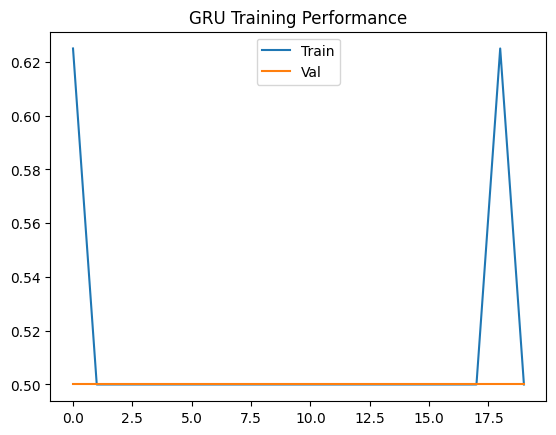

In [8]:
import os
import glob
import numpy as np
import librosa
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Input  # <--- CHANGED
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# --- CONFIGURATION ---
DATASET_PATH = './VoxCeleb1/wav'
SAMPLE_RATE = 16000
N_MFCC = 13
MAX_TIME_STEPS = 100 

# --- DATA PROCESSING (Same as LSTM) ---
def load_and_process(file_path):
    try:
        y, sr = librosa.load(file_path, sr=SAMPLE_RATE)
        y = librosa.util.normalize(y)
        y, _ = librosa.effects.trim(y, top_db=20)
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
        mfcc = mfcc.T
        if mfcc.shape[0] > MAX_TIME_STEPS:
            mfcc = mfcc[:MAX_TIME_STEPS, :]
        else:
            pad_width = MAX_TIME_STEPS - mfcc.shape[0]
            mfcc = np.pad(mfcc, ((0, pad_width), (0, 0)), mode='constant')
        return mfcc
    except:
        return None

def build_dataset_gru(root_dir):
    X, y = [], []
    speaker_dirs = [d for d in os.listdir(root_dir) if d.startswith('id')]
    print(f"Processing sequences for {len(speaker_dirs)} speakers...")
    for speaker in speaker_dirs:
        wav_files = glob.glob(os.path.join(root_dir, speaker, '**/*.wav'), recursive=True)
        for wav_path in wav_files:
            feats = load_and_process(wav_path)
            if feats is not None:
                X.append(feats)
                y.append(speaker)
    return np.array(X), np.array(y)

# --- EXECUTION ---
if __name__ == "__main__":
    if not os.path.exists(DATASET_PATH):
        print("Dataset not found.")
    else:
        # 1. Load
        X, y = build_dataset_gru(DATASET_PATH)
        
        # 2. Encode
        le = LabelEncoder()
        y_int = le.fit_transform(y)
        y_cat = to_categorical(y_int)
        
        # 3. Split
        X_train, X_test, y_train, y_test = train_test_split(X, y_cat, test_size=0.2, random_state=42)
        
        # 4. GRU Model Architecture
        model = Sequential([
            Input(shape=(MAX_TIME_STEPS, N_MFCC)),
            
            # GRU Layer
            # return_sequences=False -> We only want the final state for classification
            GRU(64, return_sequences=False), 
            
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dense(len(le.classes_), activation='softmax')
        ])
        
        model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
        
        # 5. Train
        print("\nTraining GRU...")
        history = model.fit(X_train, y_train, epochs=20, batch_size=8, validation_data=(X_test, y_test))
        
        # 6. Evaluate
        loss, acc = model.evaluate(X_test, y_test)
        print(f"\nTest Accuracy: {acc*100:.2f}%")
        
        # Plot
        plt.plot(history.history['accuracy'], label='Train')
        plt.plot(history.history['val_accuracy'], label='Val')
        plt.title('GRU Training Performance')
        plt.legend()
        plt.show()